In [5]:
import random
import time
import matplotlib.pyplot as plt
from IPython.display import clear_output
from matplotlib.patches import Rectangle

class Passenger:
    def __init__(self, pid, row, seat, luggage_delay=None):
        self.pid = pid
        self.row = row 
        self.seat = seat 
        self.x = -1
        self.y = None
        self.seated = False
        self.luggage_delay = luggage_delay if luggage_delay is not None else random.randint(1, 4)
        self.remaining_delay = self.luggage_delay

    def __repr__(self):
        return f"Passenger(row={self.row}, seat={self.seat}, seated={self.seated})" #learned from cell class in HW02

In [13]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch #from HW02 show function
import time #from HW02 
from IPython.display import clear_output #from HW02 
import random

class Plane:
    def __init__(self, num_rows):
    #seat layout is where you want seats (for example [3, 3] would be 3 seats on either side
        self.num_rows = num_rows
        self.seat_layout = [3, 3]
        self.passengers = []
        self.seat_letters = ["A", "B", "C", "D", "E", "F"]
        self.aisle_y = 3
        self.entrance_y = self.aisle_y
        
    #creates a dictionary which holds each indivdual seat and row as a touple key who's value is either not filled(None) or filled
        self.seats = {}
        for row in range(1, num_rows+1):
            for seat in self.seat_letters:
                self.seats[(row, seat)] = None

    #returns the y value for a passengers seat given the letter on their ticket
    def get_seat_y(self, seat):
        seat_y = {'A':0, 'B':1, 'C':2, 'D':4, 'E':5, 'F':6}
        return seat_y[seat]

    #adds passengers to the first spot in the aisle of the plane
    def add_passenger(self, passenger):
        passenger.y = self.entrance_y
        self.passengers.append(passenger)

    #checks if passengers are at their seat and if so has them sit and fill the seat
    def sit_passenger(self, passenger):
        if self.seats[(passenger.row, passenger.seat)] is None:
            self.seats[(passenger.row, passenger.seat)] = passenger
            passenger.seated = True
            return True
        return False

#AI used to learn how to add collision rules, was originally just p.x += 1 without any collision conditions
#Source: OpenAI. (2025). ChatGPT-5. Accessed from https://chatgpt.com/ on Nov 13, 2025
#Prompt: "How should I add collision rules to passengers in a plane boarding simulation"

    #runs one step of the simulation, checks if there are any passengers in the target row of the step, "any" returns True if anything in its function
    #also returns true so we are able to check if there are passengers ahead and "if not" the simulation moves the first passenger to that spot
    #also does not stop passengers if there is technically a passenger ahead but they are seated like it would be on a real plane.
    def step(self):
        for p in self.passengers:
            if p.seated:
                continue
            if p.x < 0:
                if not any(other.x == 0 and other.y == self.entrance_y and not other.seated for other in self.passengers):
                    p.x = 0
                continue
            if p.x < p.row - 1:
                next_x = p.x + 1
                if not any(other.x == next_x and other.y == p.y and not other.seated for other in self.passengers):
                    p.x = next_x
                continue
            seat_y = self.get_seat_y(p.seat)
            if p.y < seat_y:
                next_y = p.y + 1
                if not any(other.x == p.x and other.y == next_y and not other.seated for other in self.passengers):
                    p.y = next_y
            elif p.y > seat_y:
                next_y = p.y - 1
                if not any(other.x == p.x and other.y == next_y and not other.seated for other in self.passengers):
                    p.y = next_y
            else:
                self.sit_passenger(p)

    #some of the show code is a modified version of the code learned from HW02 Conway's Game of Life visualization
    #loops through all seats on the plane with key: (row, seat), with a value of either None or a passenger object
    #next it converts the seat letter to a integer coordinate on the plot like 'A':0
    #next plots the seats a certain color depending on whether or not the seat is full and plots the passengers as red 
    #next makes sure to show the legend with the correct colors with code modified from HW02's show function
    #finally uses plt.grid to plot the full grid and size of the plot
    def show(self):
        for (row, seat), passenger in self.seats.items():
            y = self.get_seat_y(seat)
            color = 'green' if passenger else 'white'
            plt.scatter(row - 1, y, s=500, c=color, edgecolors='black', zorder=1)

        for p in self.passengers:
            if p.seated == False:
                plt.scatter(p.x, p.y, s=500, c='red', edgecolors='black', zorder=2)
    
        plt.legend(
            handles=[
                Patch(facecolor='white', edgecolor="black", label="Empty Seat"),
                Patch(facecolor='green', edgecolor="black", label="Full Seat"),
                Patch(facecolor='red', edgecolor="black", label="Passenger in Aisle")
            ],
            bbox_to_anchor=(1.25, 1)
        )
        plt.grid()
        plt.xticks(range(self.num_rows))
        plt.yticks(range(7))
        plt.xlim(-1, self.num_rows)
        plt.ylim(-1, 7)
        plt.show()

    #learned from smooth animation code in HW02 Q2.5, "while not all" makes sure it runs until all passengers are seated
    def run(self):
        start = time.time()
        while not all(p.seated for p in self.passengers):
            clear_output(wait=True)
            self.show()
            time.sleep(0.1)
            
        clear_output(wait=True)
        self.show()
        end = time.time()
        print(f'It took {round(end-start,1)} seconds')





        
#AI version of the visualization if you want a nicer visualization than what I came up with
#Source: OpenAI. (2025). ChatGPT-5. Accessed from https://chatgpt.com/ on Nov 13, 2025
#Prompt: (fed in an exact copy of the code above) "do not change ANY of the above code, create a visualization function for the class"
    
    def show_AI(self, step_num=None):
        """Visualize the plane layout and passengers."""
        fig, ax = plt.subplots(figsize=(self.num_rows / 2, 4))
        seat_size = 0.9

        # Draw seats
        for row in range(1, self.num_rows + 1):
            for seat in self.seat_letters:
                x = row - 1
                y = self.get_seat_y(seat)
                passenger = self.seats[(row, seat)]
                color = "lightgreen" if passenger else "white"
                rect = Rectangle((x, y), seat_size, seat_size, facecolor=color, edgecolor="black")
                ax.add_patch(rect)
                ax.text(x + 0.45, y + 0.45, seat, ha="center", va="center", fontsize=8)

        # Draw aisle
        for row in range(self.num_rows):
            rect = Rectangle((row, self.aisle_y), seat_size, seat_size,
                             facecolor="lightgray", edgecolor="black")
            ax.add_patch(rect)

        # Draw passengers in the aisle (not yet seated)
        for p in self.passengers:
            if not p.seated:
                ax.scatter(p.x + 0.45, p.y + 0.45, c="red", s=100, edgecolors="black", zorder=3)

        # Beautify
        ax.set_aspect("equal")
        ax.set_xlim(-1.5, self.num_rows)
        ax.set_ylim(-0.5, 7)
        ax.invert_yaxis()
        ax.axis("off")

        # Optional title
        if step_num is not None:
            ax.set_title(f"Boarding Step {step_num}")
        else:
            ax.set_title("Plane Boarding Visualization")

        plt.show()

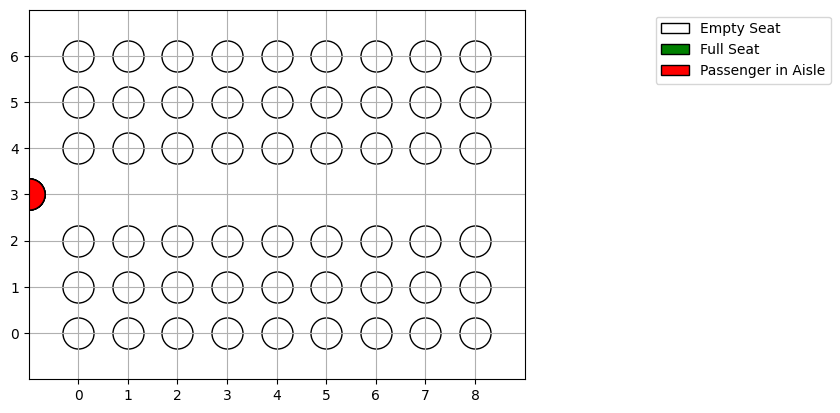

In [ ]:
boeing = Plane(num_rows=9)

passengers = [
    Passenger(1, 3, "A"),
    Passenger(2, 4, "E"),
    Passenger(3, 2, "C"),
    Passenger(4, 5, "B"),
    Passenger(5, 6, "F"),
    Passenger(6, 8, "D"),
    Passenger(7, 6, "E")
]

# Add passengers to the plane
for p in passengers:
    boeing.add_passenger(p)

# Run the simulation
boeing.run()

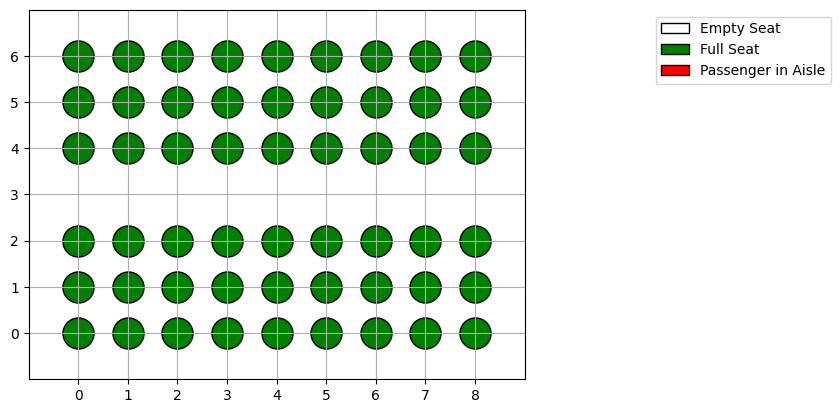

All passengers seated in: 66 steps!
It took 44.948771715164185 seconds


In [12]:
full_boeing = Plane(num_rows=9)

ordered_full_passengers = [
    Passenger(1, 1, "A"),
    Passenger(2, 1, "B"),
    Passenger(3, 1, "C"),
    Passenger(4, 1, "D"),
    Passenger(5, 1, "E"),
    Passenger(6, 1, "F"),

    Passenger(7, 2, "A"),
    Passenger(8, 2, "B"),
    Passenger(9, 2, "C"),
    Passenger(10, 2, "D"),
    Passenger(11, 2, "E"),
    Passenger(12, 2, "F"),

    Passenger(13, 3, "A"),
    Passenger(14, 3, "B"),
    Passenger(15, 3, "C"),
    Passenger(16, 3, "D"),
    Passenger(17, 3, "E"),
    Passenger(18, 3, "F"),

    Passenger(19, 4, "A"),
    Passenger(20, 4, "B"),
    Passenger(21, 4, "C"),
    Passenger(22, 4, "D"),
    Passenger(23, 4, "E"),
    Passenger(24, 4, "F"),

    Passenger(25, 5, "A"),
    Passenger(26, 5, "B"),
    Passenger(27, 5, "C"),
    Passenger(28, 5, "D"),
    Passenger(29, 5, "E"),
    Passenger(30, 5, "F"),

    Passenger(31, 6, "A"),
    Passenger(32, 6, "B"),
    Passenger(33, 6, "C"),
    Passenger(34, 6, "D"),
    Passenger(35, 6, "E"),
    Passenger(36, 6, "F"),

    Passenger(37, 7, "A"),
    Passenger(38, 7, "B"),
    Passenger(39, 7, "C"),
    Passenger(40, 7, "D"),
    Passenger(41, 7, "E"),
    Passenger(42, 7, "F"),

    Passenger(43, 8, "A"),
    Passenger(44, 8, "B"),
    Passenger(45, 8, "C"),
    Passenger(46, 8, "D"),
    Passenger(47, 8, "E"),
    Passenger(48, 8, "F"),

    Passenger(49, 9, "A"),
    Passenger(50, 9, "B"),
    Passenger(51, 9, "C"),
    Passenger(52, 9, "D"),
    Passenger(53, 9, "E"),
    Passenger(54, 9, "F")
]


# Add passengers to the plane
for p in ordered_full_passengers:
    full_boeing.add_passenger(p)

# Run the simulation
full_boeing.run()

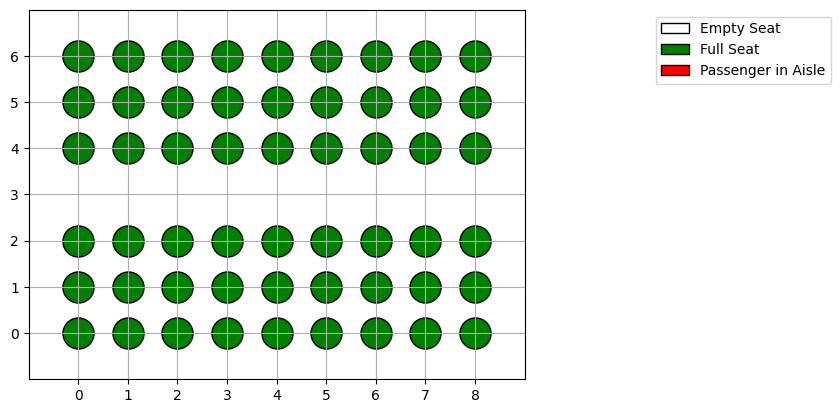

KeyboardInterrupt: 

In [11]:
full_reverse_order_boeing = Plane(num_rows=9)

reverse_full_passengers = [
    Passenger(54, 9, "F"),
    Passenger(53, 9, "E"),
    Passenger(52, 9, "D"),
    Passenger(51, 9, "C"),
    Passenger(50, 9, "B"),
    Passenger(49, 9, "A"),

    Passenger(48, 8, "F"),
    Passenger(47, 8, "E"),
    Passenger(46, 8, "D"),
    Passenger(45, 8, "C"),
    Passenger(44, 8, "B"),
    Passenger(43, 8, "A"),

    Passenger(42, 7, "F"),
    Passenger(41, 7, "E"),
    Passenger(40, 7, "D"),
    Passenger(39, 7, "C"),
    Passenger(38, 7, "B"),
    Passenger(37, 7, "A"),

    Passenger(36, 6, "F"),
    Passenger(35, 6, "E"),
    Passenger(34, 6, "D"),
    Passenger(33, 6, "C"),
    Passenger(32, 6, "B"),
    Passenger(31, 6, "A"),

    Passenger(30, 5, "F"),
    Passenger(29, 5, "E"),
    Passenger(28, 5, "D"),
    Passenger(27, 5, "C"),
    Passenger(26, 5, "B"),
    Passenger(25, 5, "A"),

    Passenger(24, 4, "F"),
    Passenger(23, 4, "E"),
    Passenger(22, 4, "D"),
    Passenger(21, 4, "C"),
    Passenger(20, 4, "B"),
    Passenger(19, 4, "A"),

    Passenger(18, 3, "F"),
    Passenger(17, 3, "E"),
    Passenger(16, 3, "D"),
    Passenger(15, 3, "C"),
    Passenger(14, 3, "B"),
    Passenger(13, 3, "A"),

    Passenger(12, 2, "F"),
    Passenger(11, 2, "E"),
    Passenger(10, 2, "D"),
    Passenger(9, 2, "C"),
    Passenger(8, 2, "B"),
    Passenger(7, 2, "A"),

    Passenger(6, 1, "F"),
    Passenger(5, 1, "E"),
    Passenger(4, 1, "D"),
    Passenger(3, 1, "C"),
    Passenger(2, 1, "B"),
    Passenger(1, 1, "A")
]



# Add passengers to the plane
for p in reverse_full_passengers:
    full_reverse_order_boeing.add_passenger(p)

# Run the simulation
full_reverse_order_boeing.run()

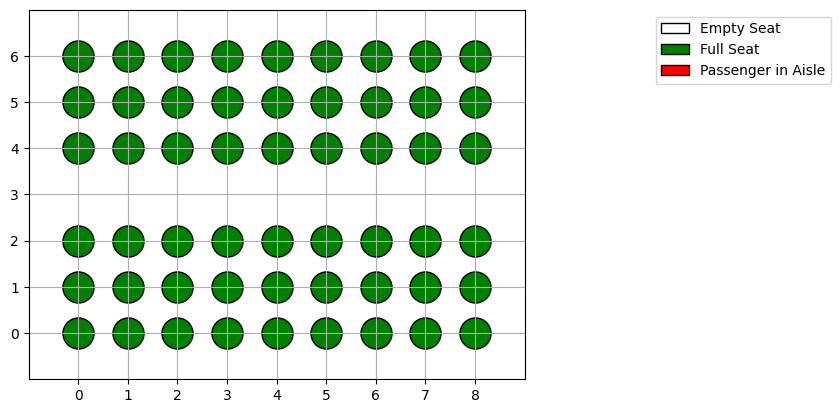

All passengers seated in: 56 steps!
It took 39.45429444313049 seconds


In [11]:
#Window-Middle-Aisle Boarding method

for p in passengers:
    boeing.add_passenger(p)
    
wilma_boeing = Plane(num_rows=9)

# Full list of passengers 
wilma_passengers = [
    Passenger(1, 1, "A"),
    Passenger(2, 1, "B"),
    Passenger(3, 1, "C"),
    Passenger(4, 1, "D"),
    Passenger(5, 1, "E"),
    Passenger(6, 1, "F"),

    Passenger(7, 2, "A"),
    Passenger(8, 2, "B"),
    Passenger(9, 2, "C"),
    Passenger(10, 2, "D"),
    Passenger(11, 2, "E"),
    Passenger(12, 2, "F"),

    Passenger(13, 3, "A"),
    Passenger(14, 3, "B"),
    Passenger(15, 3, "C"),
    Passenger(16, 3, "D"),
    Passenger(17, 3, "E"),
    Passenger(18, 3, "F"),

    Passenger(19, 4, "A"),
    Passenger(20, 4, "B"),
    Passenger(21, 4, "C"),
    Passenger(22, 4, "D"),
    Passenger(23, 4, "E"),
    Passenger(24, 4, "F"),

    Passenger(25, 5, "A"),
    Passenger(26, 5, "B"),
    Passenger(27, 5, "C"),
    Passenger(28, 5, "D"),
    Passenger(29, 5, "E"),
    Passenger(30, 5, "F"),

    Passenger(31, 6, "A"),
    Passenger(32, 6, "B"),
    Passenger(33, 6, "C"),
    Passenger(34, 6, "D"),
    Passenger(35, 6, "E"),
    Passenger(36, 6, "F"),

    Passenger(37, 7, "A"),
    Passenger(38, 7, "B"),
    Passenger(39, 7, "C"),
    Passenger(40, 7, "D"),
    Passenger(41, 7, "E"),
    Passenger(42, 7, "F"),

    Passenger(43, 8, "A"),
    Passenger(44, 8, "B"),
    Passenger(45, 8, "C"),
    Passenger(46, 8, "D"),
    Passenger(47, 8, "E"),
    Passenger(48, 8, "F"),

    Passenger(49, 9, "A"),
    Passenger(50, 9, "B"),
    Passenger(51, 9, "C"),
    Passenger(52, 9, "D"),
    Passenger(53, 9, "E"),
    Passenger(54, 9, "F")
]

window_seats = ["A", "F"]
middle_seats = ["B", "E"]
aisle_seats = ["C", "D"]

#AI-generated function for segregating passengers into rows
#Source: OpenAI. (2025). ChatGPT-5. Accessed from https://chatgpt.com/ on Nov 19, 2025
#Prompt: "Explain how to use a key to choose passenger seating order"

wilma_sorted = sorted(
    wilma_passengers,
    key=lambda p: (
        # Assign a group number based on seat type:
        # 0 = window, 1 = middle, 2 = aisle
        0 if p.seat in window_seats else
        1 if p.seat in middle_seats else
        2,

        # Sort rows in reverse order (back to front)
        # Using negative row number achieves descending order
        -p.row
    )
)

for p in wilma_sorted:
    wilma_boeing.add_passenger(p)

# Run simulation
wilma_boeing.run()